In [ ]:
!pip -q install huggingface_hub pyarrow


In [ ]:
from huggingface_hub import hf_hub_download

path = hf_hub_download(
    repo_id="Shofo/shofo-tiktok-general-small",
    filename="metadata.parquet",
    repo_type="dataset"
)

print(path)

/root/.cache/huggingface/hub/datasets--Shofo--shofo-tiktok-general-small/snapshots/93625fe8042be012276b2d88fd27860c4ee68200/metadata.parquet


In [ ]:
import pandas as pd

df = pd.read_parquet(path)

print(df.shape)
display(df.head(5))

(57960, 17)


,file_name,video_id,web_url,creator,transcript,description,hashtags,sticker_text,comments,engagement_metrics,date_posted,language,fps,resolution,duration_ms,is_ai_generated,is_ad
0,videos/31/7350916080610643231.mp4,7350916080610643231,https://www.tiktok.com/@lt1_cortez/video/73509...,lt1_cortez,None,🙏🏼 #parati #fyp #carsoftiktok #greenscreen #xy...,"[""parati""]","[""Dios, si me estoy equivocando, corrigeme, si...","[{""cid"": ""7352452026457342726"", ""text"": ""Con l...","{""play_count"": 8948070, ""like_count"": 789584, ...",2024-03-27 05:50:09+00:00,"{""desc_language"": ""un"", ""sticker_language"": ""e...",30.00,1080x1920,8434,False,False
1,videos/63/7596163428251749663.mp4,7596163428251749663,https://www.tiktok.com/@queenmexclips/video/75...,queenmexclips,None,todo que ver 🔥 🫦😍@YsraelBarajas #ysraelbarajas...,"[""ysraelbarajas""]","[""\ud83e\udee6\ud83d\ude0d"", ""@YsraelBarajas ""]","[{""cid"": ""7596737387833901831"", ""text"": ""ME PU...","{""play_count"": 5176, ""like_count"": 316, ""comme...",2026-01-17 03:14:03+00:00,"{""desc_language"": ""es"", ""sticker_language"": ""u...",27.00,1048x1860,18778,False,False
2,videos/39/7313673452668439839.mp4,7313673452668439839,https://www.tiktok.com/@_zuleimaperez/video/73...,_zuleimaperez,None,lindo detalle de gerberas 🥺 🌸 #parati #mexican...,"[""parati""]","[""POV: you\u2019re in Mexico and he still find...","[{""cid"": ""7313935034871399211"", ""text"": ""I hop...","{""play_count"": 5748920, ""like_count"": 799384, ...",2023-12-17 21:08:39+00:00,"{""desc_language"": ""es"", ""sticker_language"": ""e...",29.00,1080x1920,20534,False,False
3,videos/78/7324533804658478378.mp4,7324533804658478378,https://www.tiktok.com/@gialover_/video/732453...,gialover_,None,omg cant believe i met you and i loved the shi...,"[""parati""]",None,"[{""cid"": ""7324545369554354987"", ""text"": ""JAMES...","{""play_count"": 8238683, ""like_count"": 804814, ...",2024-01-16 03:32:25+00:00,"{""desc_language"": ""en"", ""sticker_language"": ""u...",30.00,1080x1920,11734,False,False
4,videos/67/7278870222382075167.mp4,7278870222382075167,https://www.tiktok.com/@labellastivaliz/video/...,labellastivaliz,None,#parati #foryou #viraltiktok #foryoupage❤️❤️ #...,"[""parati""]",None,[],"{""play_count"": 22018, ""like_count"": 2411, ""com...",2023-09-15 02:14:08+00:00,"{""desc_language"": ""un"", ""sticker_language"": ""u...",30.00,1078x1918,11841,False,False


## ЧАСТЬ 0. Базовая проверка

Поищем дубликаты.

In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df["video_id"].duplicated().sum()

np.int64(0)

In [ ]:
df["file_name"].duplicated().sum()

np.int64(0)

Дубликаты не обнаружены!

### Обнаруженная проблема: отсутствие даты сбора данных

В датасете есть информация о дате и времени публикации каждого видео, однако отсутствует информация о том, когда именно были собраны данные о просмотрах, лайках и других показателях вовлечённости.

**Как это влияет на обучение модели?**

Мы не можем корректно сопоставлять популярность видео без понимания того, за какой период они набрали свои просмотры и лайки.

Например, одно видео могло набрать миллион лайков за четыре года, а другое — за несколько дней (это условный пример, а не факт из нашего датасета). Если сравнивать их только по количеству лайков, не учитывая время, которое было у каждого видео на их накопление, модель может сделать неправильные выводы о популярности контента.

Это особенно важно для нашего проекта, поскольку мы хотим предсказывать популярность видео ещё до его публикации.

**Возможное решение**

Для начала проверим первоисточник — страницу датасета и его документацию. Возможно, авторы указали дату выгрузки или период сбора данных, даже если эта информация отсутствует в самой таблице.

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 57960 entries, 0 to 57959
Data columns (total 17 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   file_name           57960 non-null  object 
 1   video_id            57960 non-null  int64  
 2   web_url             57960 non-null  object 
 3   creator             57960 non-null  object 
 4   transcript          13927 non-null  object 
 5   description         57549 non-null  object 
 6   hashtags            57960 non-null  object 
 7   sticker_text        13793 non-null  object 
 8   comments            57960 non-null  object 
 9   engagement_metrics  57960 non-null  object 
 10  date_posted         57960 non-null  object 
 11  language            57960 non-null  object 
 12  fps                 55688 non-null  float64
 13  resolution          55693 non-null  object 
 14  duration_ms         57960 non-null  int64  
 15  is_ai_generated     57960 non-null  bool   
 16  is_a

In [ ]:
datas=pd.to_datetime(df["date_posted"], errors = "coerce", utc=True)

print("maximum ", datas.max())
print("minimum " , datas.min())
print("without dates ", datas.isna().sum())

maximum  2026-01-17 09:15:29+00:00
minimum  2017-03-18 19:21:57+00:00
without dates  0


Первоисточник содержит довольно размытую формулировку о том, что показатели вовлечённости были зафиксированы во время индексации видео, однако конкретной даты не предоставляет.

Несмотря на это, мы всё ещё можем исследовать данный датасет, поскольку в нём содержится много полезной для нашего проекта информации.

**Возможное решение:** найти дату самого позднего комментария во всей выборке и использовать её как приблизительную дату сбора показателей вовлечённости.

Однако стоит учитывать, что дата последнего комментария не обязательно совпадает с датой фиксации просмотров и лайков. Поэтому такое решение будет основано на предположении, а не на подтверждённой информации.

In [ ]:
to_see = df["comments"].iloc[1]
print(type(to_see))
print(to_see[0:100])

<class 'str'>
[{"cid": "7596737387833901831", "text": "ME PUEDES SEGUIR PLISSS\ud83d\ude18\ud83e\udd70", "create_t


In [ ]:
import json
data_comment = df["comments"]
data_last_com = []

for i in data_comment:
  comments = json.loads(i)

  dicti = max((coment["create_time"] for coment in comments), default=None)
  data_last_com.append(dicti)

print(data_last_com[0:5])

[1761627862, 1768753262, 1722959167, 1711238127, None]


In [ ]:
df["last_comment_date"] = pd.to_datetime(data_last_com, unit="s", utc=True)
df.head(5)

,file_name,video_id,web_url,creator,transcript,description,hashtags,sticker_text,comments,engagement_metrics,date_posted,language,fps,resolution,duration_ms,is_ai_generated,is_ad,last_comment_date
0,videos/31/7350916080610643231.mp4,7350916080610643231,https://www.tiktok.com/@lt1_cortez/video/73509...,lt1_cortez,None,🙏🏼 #parati #fyp #carsoftiktok #greenscreen #xy...,"[""parati""]","[""Dios, si me estoy equivocando, corrigeme, si...","[{""cid"": ""7352452026457342726"", ""text"": ""Con l...","{""play_count"": 8948070, ""like_count"": 789584, ...",2024-03-27 05:50:09+00:00,"{""desc_language"": ""un"", ""sticker_language"": ""e...",30.00,1080x1920,8434,False,False,2025-10-28 05:04:22+00:00
1,videos/63/7596163428251749663.mp4,7596163428251749663,https://www.tiktok.com/@queenmexclips/video/75...,queenmexclips,None,todo que ver 🔥 🫦😍@YsraelBarajas #ysraelbarajas...,"[""ysraelbarajas""]","[""\ud83e\udee6\ud83d\ude0d"", ""@YsraelBarajas ""]","[{""cid"": ""7596737387833901831"", ""text"": ""ME PU...","{""play_count"": 5176, ""like_count"": 316, ""comme...",2026-01-17 03:14:03+00:00,"{""desc_language"": ""es"", ""sticker_language"": ""u...",27.00,1048x1860,18778,False,False,2026-01-18 16:21:02+00:00
2,videos/39/7313673452668439839.mp4,7313673452668439839,https://www.tiktok.com/@_zuleimaperez/video/73...,_zuleimaperez,None,lindo detalle de gerberas 🥺 🌸 #parati #mexican...,"[""parati""]","[""POV: you\u2019re in Mexico and he still find...","[{""cid"": ""7313935034871399211"", ""text"": ""I hop...","{""play_count"": 5748920, ""like_count"": 799384, ...",2023-12-17 21:08:39+00:00,"{""desc_language"": ""es"", ""sticker_language"": ""e...",29.00,1080x1920,20534,False,False,2024-08-06 15:46:07+00:00
3,videos/78/7324533804658478378.mp4,7324533804658478378,https://www.tiktok.com/@gialover_/video/732453...,gialover_,None,omg cant believe i met you and i loved the shi...,"[""parati""]",None,"[{""cid"": ""7324545369554354987"", ""text"": ""JAMES...","{""play_count"": 8238683, ""like_count"": 804814, ...",2024-01-16 03:32:25+00:00,"{""desc_language"": ""en"", ""sticker_language"": ""u...",30.00,1080x1920,11734,False,False,2024-03-23 23:55:27+00:00
4,videos/67/7278870222382075167.mp4,7278870222382075167,https://www.tiktok.com/@labellastivaliz/video/...,labellastivaliz,None,#parati #foryou #viraltiktok #foryoupage❤️❤️ #...,"[""parati""]",None,[],"{""play_count"": 22018, ""like_count"": 2411, ""com...",2023-09-15 02:14:08+00:00,"{""desc_language"": ""un"", ""sticker_language"": ""u...",30.00,1078x1918,11841,False,False,NaT


In [ ]:
df["Difference_time"] = (df["last_comment_date"] - datas).dt.total_seconds()/86400
df.head(5)

,file_name,video_id,web_url,creator,transcript,description,hashtags,sticker_text,comments,engagement_metrics,date_posted,language,fps,resolution,duration_ms,is_ai_generated,is_ad,last_comment_date,Difference_time
0,videos/31/7350916080610643231.mp4,7350916080610643231,https://www.tiktok.com/@lt1_cortez/video/73509...,lt1_cortez,None,🙏🏼 #parati #fyp #carsoftiktok #greenscreen #xy...,"[""parati""]","[""Dios, si me estoy equivocando, corrigeme, si...","[{""cid"": ""7352452026457342726"", ""text"": ""Con l...","{""play_count"": 8948070, ""like_count"": 789584, ...",2024-03-27 05:50:09+00:00,"{""desc_language"": ""un"", ""sticker_language"": ""e...",30.00,1080x1920,8434,False,False,2025-10-28 05:04:22+00:00,579.97
1,videos/63/7596163428251749663.mp4,7596163428251749663,https://www.tiktok.com/@queenmexclips/video/75...,queenmexclips,None,todo que ver 🔥 🫦😍@YsraelBarajas #ysraelbarajas...,"[""ysraelbarajas""]","[""\ud83e\udee6\ud83d\ude0d"", ""@YsraelBarajas ""]","[{""cid"": ""7596737387833901831"", ""text"": ""ME PU...","{""play_count"": 5176, ""like_count"": 316, ""comme...",2026-01-17 03:14:03+00:00,"{""desc_language"": ""es"", ""sticker_language"": ""u...",27.00,1048x1860,18778,False,False,2026-01-18 16:21:02+00:00,1.55
2,videos/39/7313673452668439839.mp4,7313673452668439839,https://www.tiktok.com/@_zuleimaperez/video/73...,_zuleimaperez,None,lindo detalle de gerberas 🥺 🌸 #parati #mexican...,"[""parati""]","[""POV: you\u2019re in Mexico and he still find...","[{""cid"": ""7313935034871399211"", ""text"": ""I hop...","{""play_count"": 5748920, ""like_count"": 799384, ...",2023-12-17 21:08:39+00:00,"{""desc_language"": ""es"", ""sticker_language"": ""e...",29.00,1080x1920,20534,False,False,2024-08-06 15:46:07+00:00,232.78
3,videos/78/7324533804658478378.mp4,7324533804658478378,https://www.tiktok.com/@gialover_/video/732453...,gialover_,None,omg cant believe i met you and i loved the shi...,"[""parati""]",None,"[{""cid"": ""7324545369554354987"", ""text"": ""JAMES...","{""play_count"": 8238683, ""like_count"": 804814, ...",2024-01-16 03:32:25+00:00,"{""desc_language"": ""en"", ""sticker_language"": ""u...",30.00,1080x1920,11734,False,False,2024-03-23 23:55:27+00:00,67.85
4,videos/67/7278870222382075167.mp4,7278870222382075167,https://www.tiktok.com/@labellastivaliz/video/...,labellastivaliz,None,#parati #foryou #viraltiktok #foryoupage❤️❤️ #...,"[""parati""]",None,[],"{""play_count"": 22018, ""like_count"": 2411, ""com...",2023-09-15 02:14:08+00:00,"{""desc_language"": ""un"", ""sticker_language"": ""u...",30.00,1078x1918,11841,False,False,NaT,NaN


In [ ]:
df["Difference_time"].describe()

,Difference_time
count,"57,296.00"
mean,239.04
std,389.17
min,0.00
25%,27.58
50%,70.96
75%,264.89
max,"2,754.26"


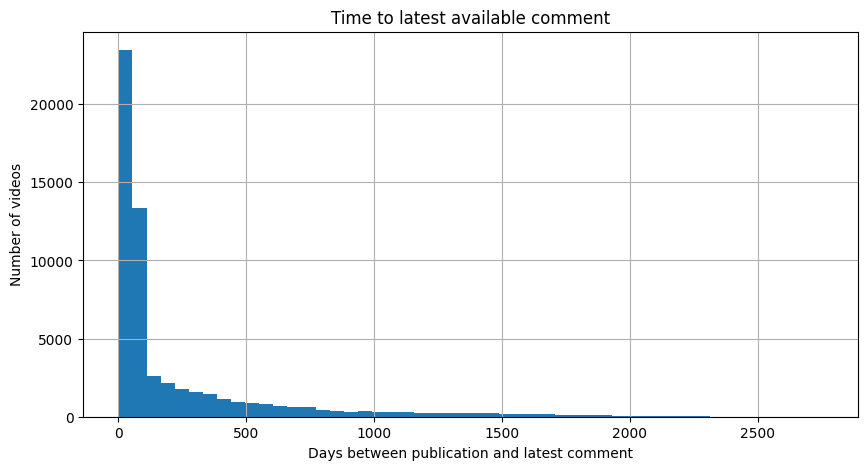

In [ ]:
import matplotlib.pyplot as plt

df["Difference_time"].hist(bins=50, figsize=(10, 5))

plt.xlabel("Days between publication and latest comment")
plt.ylabel("Number of videos")
plt.title("Time to latest available comment")
plt.show()

Видим скошенные вправо данные

In [ ]:
df["last_comment_date"].dt.date.value_counts().head(20)

,count
last_comment_date,
2026-01-18,1007
2026-01-19,779
2026-01-17,766
2026-01-16,528
2026-01-15,441
2026-01-14,387
2026-01-13,361
2026-01-12,179
2026-01-11,176


In [ ]:
print("maximum", max(df["last_comment_date"]))

maximum 2026-01-19 13:25:42+00:00


Как было сказано ранее, в первоисточнике отсутствует информация о том, когда именно были собраны данные. Поэтому в рамках нашего анализа будем предполагать, что данные были выгружены во второй половине дня 19.01.2026, поскольку самый поздний комментарий во всём датасете датирован 19.01.2026, 13:25:42 UTC.

Однако стоит учитывать, что дата последнего комментария не обязательно совпадает с датой сбора статистики просмотров и лайков. Поэтому 19.01.2026 будем использовать как предполагаемую, а не подтверждённую дату выгрузки данных.

### ЧАСТЬ 1. Изучаем структуру данных. Начало чекпоинта 2.

In [ ]:
df.head(3)

,file_name,video_id,web_url,creator,transcript,description,hashtags,sticker_text,comments,engagement_metrics,date_posted,language,fps,resolution,duration_ms,is_ai_generated,is_ad,last_comment_date,Difference_time
0,videos/31/7350916080610643231.mp4,7350916080610643231,https://www.tiktok.com/@lt1_cortez/video/73509...,lt1_cortez,None,🙏🏼 #parati #fyp #carsoftiktok #greenscreen #xy...,"[""parati""]","[""Dios, si me estoy equivocando, corrigeme, si...","[{""cid"": ""7352452026457342726"", ""text"": ""Con l...","{""play_count"": 8948070, ""like_count"": 789584, ...",2024-03-27 05:50:09+00:00,"{""desc_language"": ""un"", ""sticker_language"": ""e...",30.00,1080x1920,8434,False,False,2025-10-28 05:04:22+00:00,579.97
1,videos/63/7596163428251749663.mp4,7596163428251749663,https://www.tiktok.com/@queenmexclips/video/75...,queenmexclips,None,todo que ver 🔥 🫦😍@YsraelBarajas #ysraelbarajas...,"[""ysraelbarajas""]","[""\ud83e\udee6\ud83d\ude0d"", ""@YsraelBarajas ""]","[{""cid"": ""7596737387833901831"", ""text"": ""ME PU...","{""play_count"": 5176, ""like_count"": 316, ""comme...",2026-01-17 03:14:03+00:00,"{""desc_language"": ""es"", ""sticker_language"": ""u...",27.00,1048x1860,18778,False,False,2026-01-18 16:21:02+00:00,1.55
2,videos/39/7313673452668439839.mp4,7313673452668439839,https://www.tiktok.com/@_zuleimaperez/video/73...,_zuleimaperez,None,lindo detalle de gerberas 🥺 🌸 #parati #mexican...,"[""parati""]","[""POV: you\u2019re in Mexico and he still find...","[{""cid"": ""7313935034871399211"", ""text"": ""I hop...","{""play_count"": 5748920, ""like_count"": 799384, ...",2023-12-17 21:08:39+00:00,"{""desc_language"": ""es"", ""sticker_language"": ""e...",29.00,1080x1920,20534,False,False,2024-08-06 15:46:07+00:00,232.78


In [ ]:
(df.describe(include="all"))

,file_name,video_id,web_url,creator,transcript,description,hashtags,sticker_text,comments,engagement_metrics,date_posted,language,fps,resolution,duration_ms,is_ai_generated,is_ad,last_comment_date,Difference_time
count,57960,"57,960.00",57960,57960,13927,57549,57960,13793,57960,57960,57960,57960,"55,688.00",55693,"57,960.00",57960,57960,57296,"57,296.00"
unique,57960,NaN,57960,41133,13815,56194,13106,13583,57297,57959,57949,4889,NaN,1669,NaN,2,1,NaN,NaN
top,videos/31/7350916080610643231.mp4,NaN,https://www.tiktok.com/@lt1_cortez/video/73509...,espn,Nothing beats a jet 2 holiday. And right now y...,#CapCut,"[""fyp""]","[""@cookasyoufeelit""]",[],"{""play_count"": 60, ""like_count"": 0, ""comment_c...",2023-04-11 04:58:15+00:00,"{""desc_language"": ""en"", ""sticker_language"": ""u...",NaN,720x1280,NaN,False,False,NaN,NaN
freq,1,NaN,1,299,11,158,7846,13,664,2,2,10060,NaN,17872,NaN,57770,57960,NaN,NaN
mean,NaN,"7,242,002,450,633,472,000.00",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,33.18,NaN,"37,131.70",NaN,NaN,2024-02-01 10:15:44.313198336+00:00,239.04
min,NaN,"207,711,171,184,005,120.00",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00,NaN,0.00,NaN,NaN,2018-12-26 00:39:00+00:00,0.00
25%,NaN,"7,049,724,658,121,317,376.00",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.00,NaN,"11,834.00",NaN,NaN,2022-08-17 21:54:36+00:00,27.58
50%,NaN,"7,255,773,963,014,540,288.00",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.00,NaN,"20,567.00",NaN,NaN,2024-08-25 21:50:20+00:00,70.96
75%,NaN,"7,452,501,390,128,069,632.00",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.00,NaN,"53,914.50",NaN,NaN,2025-09-07 11:14:19+00:00,264.89
max,NaN,"7,596,256,381,959,785,472.00",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,60.00,NaN,"3,600,034.00",NaN,NaN,2026-01-19 13:25:42+00:00,"2,754.26"


In [ ]:
print(df.shape)

(57960, 19)


In [ ]:

missing = df.isna().sum()

pd.DataFrame({"Missing_count": missing, "Missing_percent": (missing/len(df) * 100), })[missing>0]

,Missing_count,Missing_percent
transcript,44033,75.97
description,411,0.71
sticker_text,44167,76.20
fps,2272,3.92
resolution,2267,3.91
last_comment_date,664,1.15
Difference_time,664,1.15


# Оценка пропущенных данных

В целом пропусков, судя по метрикам, не так много. Но, как будет понятно ниже, буквально на слово isna() верить не стоит, потому что между отсутствующими и пустыми значениями есть существенная разница.

Поэтому судить о количестве пропусков только на основании isna() недостаточно. Для полноценного анализа качества данных нам придётся копнуть немного глубже.

На основании isna() видим следующее:

engagement_metrics — пропусков нет. Отлично! Это очень важная для нас колонка, поскольку в ней находятся показатели просмотров, лайков и другой вовлечённости. Однако отсутствие пропусков в самой колонке ещё не означает, что все показатели внутри неё заполнены корректно.

description — в целом пропусков меньше 1% от общего количества видео в нашем датасете. Это обнадёживает, поскольку описание видео может оказаться полезным признаком для нашей модели.

hashtags — пропусков нет. Но я посмотрела и оценила качество хештегов, представленных в этой колонке, и обнаружила, что они не всегда полные. То есть для решения и улучшения этой проблемы я буду сопоставлять хештеги с описаниями видео, поскольку полный список хештегов может находиться именно там.

Две последние колонки — last_comment_date и Difference_time — были добавлены мной в результате первичного анализа. Они содержат по 664 пропуска. Изначально я предположила, что это означает отсутствие комментариев у 664 видео, хотя в исходной колонке comments вообще нет пропусков. Довольно странно, правда? К этому вопросу я вернусь чуть ниже.

sticker_text — пропущено очень много данных. А информация здесь важная для нашего проекта, поскольку мы хотим предсказывать популярность видео ещё до публикации. Текст, расположенный непосредственно на видео, может существенно влиять на привлечение внимания зрителей. Поэтому необходимо дополнительно проверить, почему здесь столько пропусков: действительно ли на видео отсутствует текст или система просто не смогла его распознать.

transcript — здесь ситуация похожая: отсутствует примерно 76% значений. Это довольно много, особенно если мы захотим анализировать речь в видео. Но пока нельзя утверждать, что во всех этих роликах отсутствует речь. Возможно, транскрипция просто не была выполнена или не удалась.

date_posted — все даты на месте, что очень хорошо. Особенно учитывая, что ранее мы уже столкнулись с проблемой отсутствия точной даты сбора показателей вовлечённости.

# Дополнительная проверка колонки comments

Как мы обсуждали ранее, согласно isna(), в колонке comments нет пропусков. Однако эта проверка не учитывает пустые списки.

То есть isna() видит значение "[]" и считает, что ячейка заполнена. И формально это действительно так: значение существует. Но сам список пустой, а значит, никакой информации о комментариях внутри него нет.

И вот мы видим доказательство этого предположения:

In [ ]:
(df["comments"] == "[]").sum()

np.int64(664)

Получается, что в колонке comments у нас есть 664 пустых JSON-списка, которые isna() не определяет как пропуски.

Это также объясняет, почему в созданных мной колонках last_comment_date и Difference_time появилось ровно 664 отсутствующих значения. Когда список комментариев пустой, мы не можем найти дату последнего комментария, поэтому сохраняем None, который затем преобразуется в NaT.

Но здесь есть ещё одна тонкость: пустой список сохранённых комментариев не обязательно означает, что у видео вообще не было комментариев на TikTok. Возможно, они просто не были включены в выгрузку.

Вывод: проверка через isna() — хороший первый шаг, но её недостаточно для полноценной оценки качества данных. Нужно дополнительно изучать содержимое колонок, особенно если внутри них хранятся JSON-строки, списки или другие вложенные структуры.

In [ ]:
print(type(df["engagement_metrics"].iloc[0]))
print(df["engagement_metrics"].iloc[0])

<class 'str'>
{"play_count": 8948070, "like_count": 789584, "comment_count": 1451, "share_count": 38604, "collect_count": 126905, "repost_count": 0, "download_count": 235172, "whatsapp_share_count": 15737}


давайте посмотри так важную там метрику енгеджмент. Все ли хорошо заполнено и есть ли настоящие пропуски или исна нам показывает все верно:

In [ ]:
absence_play_count=0
absence_like_count=0
absence_comment_count=0
absence_share_count=0
absence_collect_count=0
absence_repost_count = 0
absence_download_count = 0
absence_whatsapp_share_count = 0

for i in df["engagement_metrics"]:
  dicts_engagement = json.loads(i)

  if "play_count" not in dicts_engagement:
    absence_play_count+=1
  if "like_count" not in dicts_engagement:
    absence_like_count+=1
  if "comment_count" not in dicts_engagement:
    absence_comment_count+=1
  if "share_count" not in dicts_engagement:
    absence_share_count+=1
  if "collect_count" not in dicts_engagement:
    absence_collect_count+=1
  if "repost_count" not in dicts_engagement:
    absence_repost_count += 1
  if "download_count" not in dicts_engagement:
    absence_download_count += 1
  if "whatsapp_share_count" not in dicts_engagement:
    absence_whatsapp_share_count += 1

print("play_count:", absence_play_count)
print("like_count:", absence_like_count)
print("comment_count:", absence_comment_count)
print("share_count:", absence_share_count)
print("collect_count:", absence_collect_count)
print("repost_count:", absence_repost_count)
print("download_count:", absence_download_count)
print("whatsapp_share_count:", absence_whatsapp_share_count)

play_count: 0
like_count: 0
comment_count: 0
share_count: 0
collect_count: 0
repost_count: 0
download_count: 0
whatsapp_share_count: 0


In [ ]:
#is None?
dict_of_empty={"play_count": 0,
"like_count": 0,
"comment_count": 0,
"share_count": 0,
"collect_count": 0,
"repost_count": 0,
"download_count": 0,
"whatsapp_share_count": 0}

for i in df["engagement_metrics"]:
  dicts_engagement = json.loads(i)
  for key, value in dicts_engagement.items():
    if value is None:
      dict_of_empty[key]+=1
print(dict_of_empty)


#is negative?


dict_of_negative={"play_count": 0,
"like_count": 0,
"comment_count": 0,
"share_count": 0,
"collect_count": 0,
"repost_count": 0,
"download_count": 0,
"whatsapp_share_count": 0}

for i in df["engagement_metrics"]:
  dicts_engagement = json.loads(i)
  for key, value in dicts_engagement.items():
    if value < 0 :
      dict_of_negative[key]+=1
print(dict_of_negative)

#is 0?


dict_of_zero={"play_count": 0,
"like_count": 0,
"comment_count": 0,
"share_count": 0,
"collect_count": 0,
"repost_count": 0,
"download_count": 0,
"whatsapp_share_count": 0}

for i in df["engagement_metrics"]:
  dicts_engagement = json.loads(i)
  for key, value in dicts_engagement.items():
    if value == 0 :
      dict_of_zero[key]+=1
print(dict_of_zero)

{'play_count': 0, 'like_count': 0, 'comment_count': 0, 'share_count': 0, 'collect_count': 0, 'repost_count': 0, 'download_count': 0, 'whatsapp_share_count': 0}
{'play_count': 0, 'like_count': 0, 'comment_count': 0, 'share_count': 0, 'collect_count': 0, 'repost_count': 0, 'download_count': 0, 'whatsapp_share_count': 0}
{'play_count': 26, 'like_count': 39, 'comment_count': 277, 'share_count': 364, 'collect_count': 180, 'repost_count': 57960, 'download_count': 796, 'whatsapp_share_count': 1318}


Мы проверили важные показатели вовлечённости всех видео нашего датасета. И выяснили, что у нас нет ни отрицательных значений, ни пропусков: все необходимые ключи присутствуют, а значения `None` отсутствуют. Это очень хороший результат!

Что касается нулевых значений, то они встречаются, но это не обязательно говорит об ошибках. В реальной жизни не все видео получают комментарии, лайки или репосты. Некоторые видео могут просто не заинтересовать аудиторию, поэтому нулевые показатели вполне возможны.

Однако здесь есть одна странность: `repost_count` равен нулю абсолютно у всех 57 960 видео! Это уже вызывает вопросы. Возможно, данная метрика просто не собиралась или по какой-то причине была заполнена нулями. Поэтому использовать её для анализа популярности пока не имеет смысла.

Также мы обнаружили 26 видео с нулевым количеством просмотров.Это тоже стоит дополнительно проверить, особенно если окажется, что у видео с нулевыми просмотрами есть лайки или комментарии.

**Предварительный вывод:** показатели вовлечённости заполнены хорошо с точки зрения наличия значений и отсутствия отрицательных чисел. Однако наличие значения ещё не гарантирует его корректность. Поэтому нам необходимо продолжить проверку логических противоречий и подозрительных показателей.

### Пропуски?

Хочу отметить, что в задании Checkpoint 2 предлагается рассмотреть обработку пропущенных значений. Однако я считаю, что в нашем датасете не все пропуски следует заполнять.

Например, я не планирую искусственно заполнять пустые списки в колонке `comments`. Во-первых, таких записей относительно немного — всего 664 из 57 960 видео (примерно 1,15%). Во-вторых, отсутствие комментариев само по себе может быть полезной информацией для анализа популярности видео.

Возможно, некоторые видео просто не заинтересовали аудиторию: оказались слишком скучными, не вызвали эмоций или пользователи быстро пролистали их, не оставив комментария. Но это только моя гипотеза.

Также я считаю, что не следует искусственно изменять показатели вовлечённости в `engagement_metrics`: просмотры, лайки, комментарии и другие метрики. Именно их мы хотим исследовать и в дальнейшем предсказывать. Замена реальных нулей средними значениями или другими искусственно рассчитанными числами может исказить распределение популярности видео и повлиять на результаты обучения модели.

Поэтому на данном этапе я предпочитаю сохранить исходные значения, отдельно исследовать причины отсутствия информации и только после этого принимать решение о необходимости обработки пропусков.

**Мой предварительный вывод:** не все пропуски являются ошибками, которые обязательно нужно исправлять. Иногда отсутствие информации само по себе может быть полезным сигналом, а необоснованное заполнение данных способно принести больше вреда, чем пользы.

Обработаю пропуска для лучшего восприятия модели в столбике description

In [ ]:
new_df = df.copy()

new_df["description"] = new_df["description"].fillna("")

In [ ]:
new_df["description"].isna().sum()

np.int64(0)

ВВиду того что мне не удобно немного оперировать метриками вовлеченности в словарях, я их вынесу каждую метрику в отдельный столбик. таким образом наш датасет разрастется немного.

In [ ]:
df_more_columns = new_df.copy()

In [ ]:
metrics_eng = df_more_columns["engagement_metrics"].apply(json.loads)

metrics_to_column = pd.json_normalize(metrics_eng.tolist())

df_more_columns = pd.concat([df_more_columns.reset_index(drop=True), metrics_to_column], axis=1)

In [ ]:
df_more_columns.head(5)

,file_name,video_id,web_url,creator,transcript,description,hashtags,sticker_text,comments,engagement_metrics,...,last_comment_date,Difference_time,play_count,like_count,comment_count,share_count,collect_count,repost_count,download_count,whatsapp_share_count
0,videos/31/7350916080610643231.mp4,7350916080610643231,https://www.tiktok.com/@lt1_cortez/video/73509...,lt1_cortez,None,🙏🏼 #parati #fyp #carsoftiktok #greenscreen #xy...,"[""parati""]","[""Dios, si me estoy equivocando, corrigeme, si...","[{""cid"": ""7352452026457342726"", ""text"": ""Con l...","{""play_count"": 8948070, ""like_count"": 789584, ...",...,2025-10-28 05:04:22+00:00,579.97,8948070,789584,1451,38604,126905,0,235172,15737
1,videos/63/7596163428251749663.mp4,7596163428251749663,https://www.tiktok.com/@queenmexclips/video/75...,queenmexclips,None,todo que ver 🔥 🫦😍@YsraelBarajas #ysraelbarajas...,"[""ysraelbarajas""]","[""\ud83e\udee6\ud83d\ude0d"", ""@YsraelBarajas ""]","[{""cid"": ""7596737387833901831"", ""text"": ""ME PU...","{""play_count"": 5176, ""like_count"": 316, ""comme...",...,2026-01-18 16:21:02+00:00,1.55,5176,316,1,0,14,0,2,0
2,videos/39/7313673452668439839.mp4,7313673452668439839,https://www.tiktok.com/@_zuleimaperez/video/73...,_zuleimaperez,None,lindo detalle de gerberas 🥺 🌸 #parati #mexican...,"[""parati""]","[""POV: you\u2019re in Mexico and he still find...","[{""cid"": ""7313935034871399211"", ""text"": ""I hop...","{""play_count"": 5748920, ""like_count"": 799384, ...",...,2024-08-06 15:46:07+00:00,232.78,5748920,799384,1848,7654,35879,0,1761,1563
3,videos/78/7324533804658478378.mp4,7324533804658478378,https://www.tiktok.com/@gialover_/video/732453...,gialover_,None,omg cant believe i met you and i loved the shi...,"[""parati""]",None,"[{""cid"": ""7324545369554354987"", ""text"": ""JAMES...","{""play_count"": 8238683, ""like_count"": 804814, ...",...,2024-03-23 23:55:27+00:00,67.85,8238683,804814,1854,4309,23122,0,300,123
4,videos/67/7278870222382075167.mp4,7278870222382075167,https://www.tiktok.com/@labellastivaliz/video/...,labellastivaliz,None,#parati #foryou #viraltiktok #foryoupage❤️❤️ #...,"[""parati""]",None,[],"{""play_count"": 22018, ""like_count"": 2411, ""com...",...,NaT,NaN,22018,2411,1,0,3,0,0,0


In [ ]:
pd.options.display.float_format = "{:,.2f}".format
df_more_columns["play_count"].describe()

,play_count
count,"57,960.00"
mean,"26,569,836.61"
std,"29,417,611.88"
min,0.00
25%,"10,483,792.50"
50%,"19,188,187.00"
75%,"33,720,531.00"
max,"2,226,391,801.00"


Т.к мы анализируем видео просмотры. то все показатели считаются мною правильными ибо у нас есть такой популярный блогер на ютубе который собирает милиарды просмотров на каждом видео и даже известные певцы как кети перри тоже набирает милиарды. ТОесть огромные цифры не значат аномалия

In [ ]:
df_more_columns["like_count"].describe()

,like_count
count,"57,960.00"
mean,"3,024,866.74"
std,"2,344,439.58"
min,0.00
25%,"1,580,200.50"
50%,"2,485,002.50"
75%,"3,940,593.50"
max,"23,415,816.00"


Хочу добавить заключение к нашему анализу. считаю что такие метрики как просмотры и лайки не могут иметь порога после которого есть что считать аномалией. потому что видео когда залетаетЭ оно получает неимоверно большое количесво просмотров и лайков. и поэтому могу сказать что именно тут, в этих метриках, выбросов и аномалий нет

Необходимо проверить колонку с длительностью видео. Есть ли в ней какие то проблемы.

In [ ]:
df_more_columns["duration_ms"].describe()

,duration_ms
count,"57,960.00"
mean,"37,131.70"
std,"49,078.90"
min,0.00
25%,"11,834.00"
50%,"20,567.00"
75%,"53,914.50"
max,"3,600,034.00"


Вижу несоотвествие. видео не может быть 0 mсекунд. Будем разбираться

In [ ]:
(df_more_columns["duration_ms"]==0).sum()

np.int64(2268)

In [ ]:
(df_more_columns["duration_ms"]<0).sum()

np.int64(0)

Анализ показывает что 2268 видео у нас 0 мсекунд. так же ранее анализ показал что есть пропуски в данныъ fps — 2 272 пропуска и resolution — 2 267 пропусков. Цифры почти одинаковые. Странное совпадением. капаем глубжк и проверить есть ли тут связь!

In [ ]:
((df_more_columns["duration_ms"]==0) & (df_more_columns["resolution"].isna()) & (df_more_columns["fps"].isna())).sum()

np.int64(2267)

Опачки! Что нашли! что нашли! у нас все 2267 видео которые 0 мсекунд у них как раз нет ни фпс и резолютион. вот оно что! Давайте взглянем на них получше и посмотрим что еще у них может отсутствовать. ВОзможно это пустые видео и данные, по какой то технической ошибке были записаны без на то либо какой причины.

In [ ]:
new_df_tab_zeros = df_more_columns[(df_more_columns["duration_ms"]==0) & (df_more_columns["resolution"].isna()) & (df_more_columns["fps"].isna())].copy()

new_df_tab_zeros.head(5)

,file_name,video_id,web_url,creator,transcript,description,hashtags,sticker_text,comments,engagement_metrics,...,last_comment_date,Difference_time,play_count,like_count,comment_count,share_count,collect_count,repost_count,download_count,whatsapp_share_count
1762,videos/18/7484646865774857518.mp4,7484646865774857518,https://www.tiktok.com/@eluvskpop/video/748464...,eluvskpop,None,#goldencat #legendary #fyp #foryoupage #viral,"[""goldencat""]",None,"[{""cid"": ""7485379948300944174"", ""text"": ""Legen...","{""play_count"": 51093803, ""like_count"": 1132603...",...,2025-06-08 03:21:53+00:00,77.52,51093803,11326039,197511,945944,1317233,0,32086,3061
2165,videos/83/7486242179439004983.mp4,7486242179439004983,https://www.tiktok.com/@v4ampcarti_/video/7486...,v4ampcarti_,None,#teeth #trend #foryou #teethbeauty #braces #to...,"[""teeth""]","[""I won this trend!"", ""no I did!"", "".....""]","[{""cid"": ""7486446629013832466"", ""text"": ""nahh ...","{""play_count"": 44910399, ""like_count"": 6566498...",...,2025-06-11 10:43:55+00:00,76.53,44910399,6566498,7624,44657,373862,0,167,634
2440,videos/70/7440776971950378270.mp4,7440776971950378270,https://www.tiktok.com/@chettopuffs.yum/video/...,chettopuffs.yum,None,🙏🙏 #fyp #foryou #college #dad #foryoupage #vir...,"[""fyp""]",None,"[{""cid"": ""7440899373661537055"", ""text"": ""Yu ca...","{""play_count"": 48386720, ""like_count"": 1028025...",...,2024-11-29 19:35:45+00:00,5.42,48386720,10280253,23323,239596,536223,0,8125,1625
2540,videos/43/7547172489508474143.mp4,7547172489508474143,https://www.tiktok.com/@_daniel.jay/video/7547...,_daniel.jay,None,As a father should. #gymmotivation #dadsoftikt...,"[""gymmotivation""]",None,"[{""cid"": ""7547810253942801182"", ""text"": ""the o...","{""play_count"": 63433924, ""like_count"": 1002218...",...,2025-11-20 20:48:11+00:00,74.75,63433924,10022182,33074,403978,641374,0,10096,6352
2675,videos/87/7553633089885441287.mp4,7553633089885441287,https://www.tiktok.com/@huzz.hunterzzzz2009/vi...,huzz.hunterzzzz2009,None,#loveowls #fyp #viral #trend #relatable @Enriq...,"[""loveowls""]",None,"[{""cid"": ""7553724550808126209"", ""text"": "" [pho...","{""play_count"": 31007885, ""like_count"": 6385892...",...,2025-09-30 10:15:24+00:00,5.90,31007885,6385892,15449,1357633,457717,0,16126,12090


Моя теория была не верна. у наших видео есть данные о лайках и просмотраХ! предпологаю что сама обработка видео произошла не успешно. Нельзя оставлять модели нули. Это пагубно повлияет на ее обучение. Модель может решить что видео с нулевой длительностью могут набирать милионы просмотров. это плохо. поэтому пока нули заменяю на NaN.

In [ ]:
import numpy as np
df_next_dur_nan = df_more_columns.copy()
mask_dur_zeros = ((df_more_columns["duration_ms"]==0) & (df_more_columns["resolution"].isna()) & (df_more_columns["fps"].isna()))
df_next_dur_nan["duration_ms"] = np.where(mask_dur_zeros, np.nan, df_next_dur_nan["duration_ms"])

In [ ]:
df_next_dur_nan["duration_ms"].describe()

,duration_ms
count,"55,693.00"
mean,"38,643.15"
std,"49,481.11"
min,0.00
25%,"12,676.00"
50%,"21,779.00"
75%,"55,888.00"
max,"3,600,034.00"


In [ ]:
(df_next_dur_nan["duration_ms"]==0).sum()

np.int64(1)

In [ ]:
df_next_dur_nan["duration_ms"] = np.where((df_next_dur_nan["duration_ms"]==0), np.nan, df_next_dur_nan["duration_ms"])

In [ ]:
df_next_dur_nan["duration_ms"].describe()

,duration_ms
count,"55,692.00"
mean,"38,643.85"
std,"49,481.29"
min,"3,341.00"
25%,"12,676.00"
50%,"21,779.00"
75%,"55,888.25"
max,"3,600,034.00"


Как можно заметить даже статистика изменилась! Потому что пандас раньше учитывал нули а теперь нулей нет. и статистика получается чище. Нан не учавствует в расчетах!
После обработки минимальная известная длительность составляет 3,341 секунды, средняя увеличилась с 37,13 до 38,64 секунды, а медиана — с 20,57 до 21,78 секунды.
Таким образом, мы сохранили все 57 960 видео, но теперь явно обозначили, для каких из них настоящая длительность неизвестна. Заполнять эти пропуски придуманными значениями пока не планирую. Но в последсвии планирую скачать сами видео из датасета и обработать их. и в последствии добавить данные в таблицу(я пока не знаю как это сделать но узнаю)

## ЧАСТЬ 2. Целевая переменная и тотальное погружение в ЕДА

Весь этот анализ был интересным но Наша целевая переменная это количество просмотров. тоесть столбец "play_count". И! она не зависит ни от лайков ни от того сколько поделились ни от коментов. Потому что наша модель получает видео еще не выпущенное. А значит наше видео не имеет никакие такие метрики и судить строить модель по них мы не будем. какие данные нам нужны? вот список:
Хештеги
Описание
Резолюсьон
Текст на видео
Музыка
Длительность

Из первых частей анализа было заметно что у 76% видео текст отсутствует или не был извлечён. это ошибка дата сета. И в данный момент мое решеие это анализировать то что есть, тоесть я создам отдельную таблицу со всеми надписями на видео доступными. и эту часть буду анализировать. А остальные видео я обработаю с помощью доп программ(найду каких) и допишу доделаю дата сет до нужной кондции. А пока то что есть. И сделаю первую пробную модель предсказания видео.

In [ ]:
df_next_dur_nan.head(2)


,file_name,video_id,web_url,creator,transcript,description,hashtags,sticker_text,comments,engagement_metrics,...,last_comment_date,Difference_time,play_count,like_count,comment_count,share_count,collect_count,repost_count,download_count,whatsapp_share_count
0,videos/31/7350916080610643231.mp4,7350916080610643231,https://www.tiktok.com/@lt1_cortez/video/73509...,lt1_cortez,None,🙏🏼 #parati #fyp #carsoftiktok #greenscreen #xy...,"[""parati""]","[""Dios, si me estoy equivocando, corrigeme, si...","[{""cid"": ""7352452026457342726"", ""text"": ""Con l...","{""play_count"": 8948070, ""like_count"": 789584, ...",...,2025-10-28 05:04:22+00:00,579.97,8948070,789584,1451,38604,126905,0,235172,15737
1,videos/63/7596163428251749663.mp4,7596163428251749663,https://www.tiktok.com/@queenmexclips/video/75...,queenmexclips,None,todo que ver 🔥 🫦😍@YsraelBarajas #ysraelbarajas...,"[""ysraelbarajas""]","[""\ud83e\udee6\ud83d\ude0d"", ""@YsraelBarajas ""]","[{""cid"": ""7596737387833901831"", ""text"": ""ME PU...","{""play_count"": 5176, ""like_count"": 316, ""comme...",...,2026-01-18 16:21:02+00:00,1.55,5176,316,1,0,14,0,2,0


In [ ]:
#a little bit of simple check
print(df_next_dur_nan["sticker_text"].iloc[0])
print(df_next_dur_nan["description"].iloc[0])
print(df_next_dur_nan["hashtags"].iloc[0])

print(df_next_dur_nan["sticker_text"].iloc[1])
print(df_next_dur_nan["description"].iloc[1])
print(df_next_dur_nan["hashtags"].iloc[1])



print(type(df_next_dur_nan["hashtags"].iloc[1]))
print(type(df_next_dur_nan["sticker_text"].iloc[1]))
print(type(df_next_dur_nan["description"].iloc[1]))

["Dios, si me estoy equivocando, corrigeme, si me estoy perdiendo gu\u00edame y si me estoy rindiendo dame\nFuerzas."]
🙏🏼 #parati #fyp #carsoftiktok #greenscreen #xyzbca #viral #trending #camaro #carcommunity #audio #shorttiktok #explorepage #foryou 
["parati"]
["\ud83e\udee6\ud83d\ude0d", "@YsraelBarajas "]
todo que ver 🔥 🫦😍@YsraelBarajas #ysraelbarajas #contenido #parati #foryoupage #videoviral 
["ysraelbarajas"]
<class 'str'>
<class 'str'>
<class 'str'>


Мы видим что кононка хештеги заполнена не правильно. не все хештеги там прописаны что указаны в комментариях. И видим что коментарии так же могут быть заполнены чисто хештегами без реального описания.
Так же мой визуальный анализ некоторый выборки видео показал что у видео некоторых действительно отсутствует текст! моя теория о том что каждое видео имеет надписи не верна.Значит у нас действительно есть видео без подписей на самом видео. это меняет мой план работы. Это важно, потому что надписи на видео влияют на вовлеченность зрителя.

Мой план работы: перенести все хештеги из описания в колонку хештеги и очистить колонку описание к видео от хештегов оставим либо описание чисто либо пустую строку.

In [ ]:
import re
df_text_clean = df_next_dur_nan.copy()



df_text_clean["hashtags_clean"] = (df_text_clean["description"].fillna("").apply(lambda text: re.findall(r"#\w+", text)))

df_text_clean["description_clean"] = (df_text_clean["description"].fillna("").apply(lambda text: re.sub(r"#\w+", "", text).strip()))

df_text_clean.head(5)

,file_name,video_id,web_url,creator,transcript,description,hashtags,sticker_text,comments,engagement_metrics,...,play_count,like_count,comment_count,share_count,collect_count,repost_count,download_count,whatsapp_share_count,hashtags_clean,description_clean
0,videos/31/7350916080610643231.mp4,7350916080610643231,https://www.tiktok.com/@lt1_cortez/video/73509...,lt1_cortez,None,🙏🏼 #parati #fyp #carsoftiktok #greenscreen #xy...,"[""parati""]","[""Dios, si me estoy equivocando, corrigeme, si...","[{""cid"": ""7352452026457342726"", ""text"": ""Con l...","{""play_count"": 8948070, ""like_count"": 789584, ...",...,8948070,789584,1451,38604,126905,0,235172,15737,"[#parati, #fyp, #carsoftiktok, #greenscreen, #...",🙏🏼
1,videos/63/7596163428251749663.mp4,7596163428251749663,https://www.tiktok.com/@queenmexclips/video/75...,queenmexclips,None,todo que ver 🔥 🫦😍@YsraelBarajas #ysraelbarajas...,"[""ysraelbarajas""]","[""\ud83e\udee6\ud83d\ude0d"", ""@YsraelBarajas ""]","[{""cid"": ""7596737387833901831"", ""text"": ""ME PU...","{""play_count"": 5176, ""like_count"": 316, ""comme...",...,5176,316,1,0,14,0,2,0,"[#ysraelbarajas, #contenido, #parati, #foryoup...",todo que ver 🔥 🫦😍@YsraelBarajas
2,videos/39/7313673452668439839.mp4,7313673452668439839,https://www.tiktok.com/@_zuleimaperez/video/73...,_zuleimaperez,None,lindo detalle de gerberas 🥺 🌸 #parati #mexican...,"[""parati""]","[""POV: you\u2019re in Mexico and he still find...","[{""cid"": ""7313935034871399211"", ""text"": ""I hop...","{""play_count"": 5748920, ""like_count"": 799384, ...",...,5748920,799384,1848,7654,35879,0,1761,1563,"[#parati, #mexicantiktok, #ramo, #guanajuato, ...",lindo detalle de gerberas 🥺 🌸
3,videos/78/7324533804658478378.mp4,7324533804658478378,https://www.tiktok.com/@gialover_/video/732453...,gialover_,None,omg cant believe i met you and i loved the shi...,"[""parati""]",None,"[{""cid"": ""7324545369554354987"", ""text"": ""JAMES...","{""play_count"": 8238683, ""like_count"": 804814, ...",...,8238683,804814,1854,4309,23122,0,300,123,"[#parati, #paratii]",omg cant believe i met you and i loved the shi...
4,videos/67/7278870222382075167.mp4,7278870222382075167,https://www.tiktok.com/@labellastivaliz/video/...,labellastivaliz,None,#parati #foryou #viraltiktok #foryoupage❤️❤️ #...,"[""parati""]",None,[],"{""play_count"": 22018, ""like_count"": 2411, ""com...",...,22018,2411,1,0,3,0,0,0,"[#parati, #foryou, #viraltiktok, #foryoupage, ...",❤️❤️


Теперь посмотрим сколько у нас строк пустых в наших новых чистых колонках.

In [ ]:
print((df_text_clean["hashtags_clean"].apply(len)==0).sum())
(df_text_clean["description_clean"]=="").sum()

445


np.int64(8326)

у нас есть пустые строк в описании и они составляют примерно 14,4% от 57 960 видео.
445 видео без хештегов — примерно 0,77%.
Получается, что 99,23% видео имеют хотя бы один хештег в описании. С такими важными метриками тут мы закончили. Заполнять и придумывать ничего не буду, т.к это могут быть реальные данные и они нужны нам для обучения модели. например видео может вообще не иметь хештегов или ютуб к примеру разрешает более 60 на одно видео. описание тоже не всегда может быть это нормальное явление. Переходим к тому что написано на видео. как я сказала выше что оказалось что на видео реально нет текста! тоесть может не быть текста и это тоже заполнять ничем не надо это очень важные наблюдения. осталось только привести стобец к хорошему виду.

In [ ]:

def cleaning_text(row_text):

  if row_text is None:
    return ""

  try:
    cat = json.loads(row_text)
  except json.JSONDecodeError:
    return row_text.strip()
  cat_join = " ".join(cat)

  return cat_join.strip()

df_text_clean["sticker_text_clean"] = df_text_clean["sticker_text"].apply(cleaning_text)


In [ ]:
print(df_text_clean["sticker_text_clean"].iloc[1])
print(df_text_clean["sticker_text_clean"].iloc[10])
print(df_text_clean["sticker_text_clean"].iloc[100])
print(df_text_clean["sticker_text_clean"].iloc[1000])

🫦😍 @YsraelBarajas





In [ ]:
(df_text_clean["sticker_text_clean"]=="").sum()

np.int64(44172)

In [ ]:
print(df_text_clean["sticker_text_clean"].iloc[0])
print(df_text_clean["sticker_text_clean"].iloc[2])

Dios, si me estoy equivocando, corrigeme, si me estoy perdiendo guíame y si me estoy rindiendo dame
Fuerzas.
POV: you’re in Mexico and he still finds a way to surprise you with flowers 💐🥺


Так, теперь у нас есть хорошо читаемые надписи на видео, напомниаю что их всего около 24% от всего датасета но как мы выяснили ранее, видео действитлеьно встречаются без текста.

### ЧАСТЬ 3. Embeddings

Погружаемся все глубже. время учить бейслайн модельку. и еще немного анализа. Для эмбединга воспользуюсь уже готовой моделью.

In [ ]:
!pip -q install sentence-transformers

In [ ]:
from sentence_transformers import SentenceTransformer

model = SentenceTransformer(
    "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"
)

modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/3.89k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/645 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  471MB            

... (3 outputs left out)

tokenizer.json: reconstructing file:   0%|          |  0.00B / 9.08MB            

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

In [ ]:
df_plus_emb = df_text_clean.copy()

In [ ]:
mask_for_emb = df_plus_emb["sticker_text_clean"] !=""

In [ ]:
not_empt_text = df_plus_emb.loc[mask_for_emb, "sticker_text_clean"].tolist()

using_model = model.encode(not_empt_text, batch_size=32, show_progress_bar=True)

print("done")

Batches:   0%|          | 0/431 [00:00<?, ?it/s]

done


In [ ]:
np.save("sticker_embeddings.npy", using_model)
print(using_model.shape)

NameError: name 'using_model' is not defined

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

np.save(
    "/content/drive/MyDrive/sticker_embeddings.npy",
    using_model
)

In [ ]:
np.save(
    "sticker_video_ids.npy",
    df_plus_emb.loc[mask_for_emb, "video_id"].to_numpy()
)

In [ ]:
np.save(
    "/content/drive/MyDrive/sticker_video_ids.npy",
    df_plus_emb.loc[mask_for_emb, "video_id"].to_numpy()
)

In [ ]:
all_emb_stik = np.zeros((len(mask_for_emb), 384),
    dtype=np.float32)

all_emb_stik[mask_for_emb.to_numpy()] = using_model

NameError: name 'using_model' is not defined

In [ ]:
print(all_emb_stik.shape)

(57960, 384)


Теперь у нас есть наш текст на видео в цифрах, и моделька сможет оценить по достоинству что написано. Но у нас много нулей. чтобы модель не путалась сделаем дом признак специально указывающий на то , был ли текст предоставлен или нет вообще изначально. 1 если текст был и 0 если не было. таким образом модель будет понимать и ориентироваться.
Но тут небольшое уточнение. 1 это был доступный текст. да я проверила некоторую выборку с отсутствующим текстом и его действительно не было на видео. но всякое может быть, так же может быть и ошибка распознавания поэтому будет рассматривать 1 как был доступный нам текст. предоставленный.

In [ ]:
df_text_clean["has_sticker_text"] = mask_for_emb.astype(int)

In [ ]:
df_text_clean["has_sticker_text"].sum()

np.int64(13788)

Теперь сделаем тоже самое с описанием.

In [ ]:
mask_desc = df_plus_emb["description_clean"] != ""

In [ ]:

desc_for_model = df_plus_emb.loc[mask_desc, "description_clean"].tolist()

using_model_desc = model.encode(desc_for_model, batch_size=32, show_progress_bar=True)

Batches:   0%|          | 0/1552 [00:00<?, ?it/s]

In [ ]:
np.save("description_emb", using_model_desc)
print(using_model_desc.shape)

(49634, 384)


In [ ]:
np.save("ids_description_emb.npy", df_plus_emb.loc[mask_desc, "video_id"].to_numpy())

In [ ]:
all_descr_emb = np.zeros((len(mask_desc), 384), dtype=np.float32)

all_descr_emb[mask_desc.to_numpy()] = using_model_desc

In [ ]:
all_descr_emb.shape

(57960, 384)

In [ ]:
df_text_clean["has_description"] = mask_desc.astype(int)

In [ ]:
df_text_clean["has_description"].sum()

np.int64(49634)

Описание тоже готово!

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

import os

SAVE_DIR = "/content/drive/MyDrive/tiktok_visual_embeddings"
os.makedirs(SAVE_DIR, exist_ok=True)

Mounted at /content/drive


**Внимание!** Следующие несколько ячеек не нужно запускать повторно. Они нужны для того, чтобы скачать видео из датасета, извлечь по одному кадру на каждую секунду первых пяти секунд видео и преобразовать полученные кадры в числовые признаки с помощью готовой модели.

In [ ]:
!pip -q install transformers huggingface_hub opencv-python-headless pillow

In [ ]:
import torch
import cv2

from PIL import Image
from transformers import CLIPModel, CLIPProcessor

device = "cuda" if torch.cuda.is_available() else "cpu"

clip_model = CLIPModel.from_pretrained(
    "openai/clip-vit-base-patch32"
).to(device).eval()

processor = CLIPProcessor.from_pretrained(
    "openai/clip-vit-base-patch32"
)

print("Device:", device)

config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

... (3 outputs left out)

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

Device: cpu


In [ ]:
def extract_first_5_seconds(video_path):

    cap = cv2.VideoCapture(video_path)

    if not cap.isOpened():
        raise ValueError("Не удалось открыть видео")

    fps = cap.get(cv2.CAP_PROP_FPS)
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    if fps <= 0 or total_frames <= 0:
        cap.release()
        raise ValueError("Некорректный FPS или количество кадров")

    frames = []

    for second in range(5):

        frame_number = round(second * fps)

        if frame_number >= total_frames:
            break

        cap.set(cv2.CAP_PROP_POS_FRAMES, frame_number)

        success, frame = cap.read()

        if success:
            frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
            frames.append(Image.fromarray(frame))

    cap.release()

    if not frames:
        raise ValueError("Не удалось извлечь кадры")

    return frames

In [ ]:
def make_video_embedding(frames):

    inputs = processor(
        images=frames,
        return_tensors="pt"
    ).to(device)

    with torch.inference_mode():
        features = clip_model.get_image_features(
            pixel_values=inputs["pixel_values"]
        )

        # Совместимость с разными версиями transformers
        if not isinstance(features, torch.Tensor):
            features = features.pooler_output

        features = torch.nn.functional.normalize(
            features, dim=-1
        )

        video_embedding = features.mean(dim=0)

        video_embedding = torch.nn.functional.normalize(
            video_embedding, dim=0
        )

    return video_embedding.cpu().numpy()

In [ ]:
from huggingface_hub import hf_hub_download
from tqdm.auto import tqdm
import time

def process_videos(df, limit=100):

    sample = df.head(limit)

    for _, row in tqdm(sample.iterrows(), total=len(sample)):

        video_id = str(row["video_id"])
        file_name = row["file_name"]

        save_path = os.path.join(
            SAVE_DIR, f"{video_id}.npz"
        )

        # Уже обработано? Пропускаем!
        if os.path.exists(save_path):
            continue

        local_path = None

        try:
            local_path = hf_hub_download(
                repo_id="Shofo/shofo-tiktok-general-small",
                filename=file_name,
                repo_type="dataset",
                local_dir="/content/tiktok_temp"
            )

            frames = extract_first_5_seconds(local_path)

            embedding = make_video_embedding(frames)

            # Сначала сохраняем временный файл
            temp_path = save_path + ".tmp.npz"

            np.savez_compressed(
                temp_path,
                video_id=video_id,
                embedding=embedding,
                frames_used=len(frames)
            )

            # Только после успешного сохранения
            # переименовываем в итоговый файл
            os.replace(temp_path, save_path)

        except Exception as e:
            print(f"Ошибка у видео {video_id}: {e}")

        finally:
            # Удаляем MP4, но сохраняем embedding
            if local_path and os.path.isfile(local_path):
                os.remove(local_path)

    print("Партия завершена!")

In [ ]:
process_videos(df_plus_emb, limit=4900)

  0%|          | 0/4900 [00:00<?, ?it/s]

videos/18/7484646865774857518.mp4: reconstructing file:   0%|          |  0.00B /  303kB            

videos/18/7484646865774857518.mp4: downloading bytes:           |  0.00B            

Ошибка у видео 7484646865774857518: Не удалось открыть видео


videos/37/6983042264155032837.mp4: reconstructing file:   0%|          |  0.00B / 1.49MB            

videos/37/6983042264155032837.mp4: downloading bytes:           |  0.00B            

... (3,917 outputs left out)

videos/26/7382427467903946026.mp4: downloading bytes:           |  0.00B            

videos/56/7390414700330093856.mp4: reconstructing file:   0%|          |  0.00B /  498kB            

videos/56/7390414700330093856.mp4: downloading bytes:           |  0.00B            

videos/57/7280602292829572357.mp4: reconstructing file:   0%|          |  0.00B / 4.85MB            

К сожалению занимает очень много времени и колаб не дает просто поставить и уйти. поэтому у нас сейчас получилась выборка из почти 4 тыс видео. и на ней будем обучать первую модельку и анализировать.

Деперь для хештегов! но предварительн опреобразуем их в текст.

In [ ]:
df_plus_emb["hashtags_text"] = df_plus_emb["hashtags_clean"].apply(lambda tags: " ".join(tags) if isinstance(tags, list) else "")

In [ ]:
mask_hash = df_plus_emb["hashtags_text"] != ""

In [ ]:

hash_for_model = df_plus_emb.loc[mask_hash, "hashtags_text"].to_numpy()


In [ ]:
using_model_hash = model.encode(hash_for_model,batch_size=32,show_progress_bar=True)

using_model_hash.shape

Batches:   0%|          | 0/1798 [00:00<?, ?it/s]

(57515, 384)

In [ ]:
np.save("hashtags_emb", using_model_hash)

In [ ]:
np.save("ids_hashtags_emb.npy", df_plus_emb.loc[mask_hash, "video_id"].to_numpy())

In [ ]:
all_hash_emb = np.zeros((len(df_plus_emb), 384),dtype=np.float32)

all_hash_emb[mask_hash.to_numpy()] = using_model_hash

In [ ]:
all_hash_emb.shape

(57960, 384)

In [ ]:
df_plus_emb["has_hashtags"] = mask_hash.astype(int)
df_plus_emb["has_hashtags"].sum()

np.int64(57515)

## ЧАСТЬ 4. все готово для анали. анализируем нужные признаки.

Наша таргет это колонка с просмотрами. Соберемвсе наши признаки в одну таблицу оставив только нужные. и отдельно таргет.

In [ ]:
#target y

y = df_plus_emb["play_count"]

In [ ]:
#our embenddings
stiker_emb = np.load("sticker_embeddings.npy")
id_stiker_emb=np.load("sticker_video_ids.npy")
"""together_stik = pd.DataFrame(stiker_emb, columns=[f"stiket_{i}" for i in range(len(stiker_emb.shape[1]))])
together_stik.insert(0,"video_id", id_stiker_emb)"""

descr_emb=np.load("description_emb.npy")
id_descr_emb=np.load("ids_description_emb.npy")
"""""ogether_descr = pd.DataFrame(descr_emb, columns=[f"descr_{i}" for i in range(len(descr_emb.shape[1]))])
together_descr.insert(0, "video_id", id_descr_emb)"""

hash_emb = np.load("hashtags_emb.npy")
id_hash_emb=np.load("ids_hashtags_emb.npy")
"""together_hash = pd.DataFrame(hash_emb, columns=[f"hash_{i}" for i in range(len(hash_emb.shape[1]))])
together_hash.insert(0, "video_id", id_hash) """



all_stikers=np.zeros((len(df_plus_emb), 384), dtype=np.float32)
all_stikers[mask_for_emb.to_numpy()]=stiker_emb

all_descr=np.zeros((len(df_plus_emb), 384), dtype=np.float32)
all_descr[mask_desc.to_numpy()]=descr_emb

all_hashs=np.zeros((len(df_plus_emb), 384), dtype=np.float32)
all_hashs[mask_hash.to_numpy()]=hash_emb


In [ ]:
# table of features
X_emb=np.hstack([all_stikers, all_descr, all_hashs])

indicats = np.column_stack([mask_for_emb.to_numpy().astype(int), mask_desc.to_numpy().astype(int), mask_hash.to_numpy().astype(int)])

In [ ]:
X=np.hstack([X_emb, indicats])

Переведем в таблицу наши эмбединг визуальные. именно они наиболее важные в нашем датасете.

In [ ]:
import os


SAVE_DIR = "/content/drive/MyDrive/tiktok_visual_embeddings"

video_ids = []
video_embs = []

for file in os.listdir(SAVE_DIR):
    if file.endswith(".npz"):
        with np.load(os.path.join(SAVE_DIR, file)) as data:
            video_ids.append(str(data["video_id"].item()))
            video_embs.append(data["embedding"].copy())

video_embs = np.stack(video_embs)

print(video_embs.shape)

(4514, 512)


ввиду того что у нас не для всего дата сета есть визуальные эмбединс мы возьмем все что есть и добавим из матрицы Х остальные характеристики чтобы сделать анализ и обучить модель.

In [ ]:
video_embs_tab = pd.DataFrame(video_embs, columns=[f"video_emb_{i}" for i in range(video_embs.shape[1])])
video_embs_tab.insert(0, "video_id" ,video_ids)

In [ ]:
display(video_embs_tab.head())
print(video_embs_tab.shape)

,video_id,video_emb_0,video_emb_1,video_emb_2,video_emb_3,video_emb_4,video_emb_5,video_emb_6,video_emb_7,video_emb_8,...,video_emb_502,video_emb_503,video_emb_504,video_emb_505,video_emb_506,video_emb_507,video_emb_508,video_emb_509,video_emb_510,video_emb_511
0,7275931911489539374,-0.05,0.05,-0.06,-0.07,0.00,0.02,0.03,0.01,0.00,...,-0.02,-0.04,0.07,-0.01,-0.00,0.04,0.00,-0.04,-0.03,-0.00
1,7534099045363567885,0.01,0.03,0.00,0.03,-0.01,0.00,0.02,0.03,-0.00,...,0.02,-0.01,-0.03,-0.02,-0.01,0.02,-0.00,0.07,0.01,-0.01
2,7436963938895678766,-0.01,0.00,0.03,0.01,0.01,-0.01,-0.01,0.03,0.09,...,0.01,-0.01,-0.01,-0.01,0.01,-0.00,-0.04,-0.02,0.02,-0.02
3,7475385727895817494,-0.01,0.01,0.02,-0.04,0.01,-0.05,0.01,-0.02,0.05,...,-0.03,-0.00,-0.01,-0.01,-0.04,-0.05,-0.03,0.02,0.03,0.02
4,7180946684661337349,-0.05,-0.02,-0.02,-0.02,0.04,-0.06,-0.00,0.03,0.03,...,-0.02,-0.01,0.04,-0.01,0.03,0.02,-0.01,0.01,0.02,-0.02


(4514, 513)


In [ ]:
print("X:", X.shape)
print("df:", df.shape)
print("Visual:", video_embs_tab.shape)

X: (57960, 1155)
df: (57960, 19)
Visual: (4514, 513)


In [ ]:
X_df = pd.DataFrame(X)
X_df.insert(0, "video_id", df_plus_emb["video_id"])
X_df["video_id"] = X_df["video_id"].astype(str)
video_embs_tab["video_id"] = video_embs_tab["video_id"].astype(str)
X_full=X_df.merge(video_embs_tab, on="video_id", how="inner", validate="one_to_one")

print(X_full.shape)

(4514, 1668)


## ЧАСТЬ 5 . АНАЛИЗ(пор фин)

In [ ]:
import matplotlib.pyplot as plt

In [ ]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

Videos: 4514
Total features: 1667
Visual features: 512
Missing values: 0
Duplicate IDs: 0


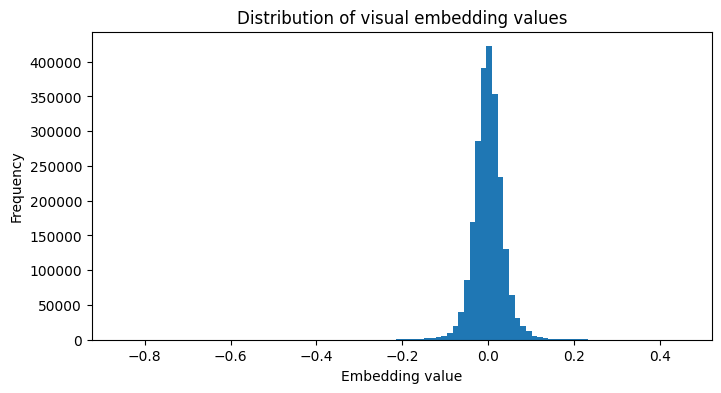

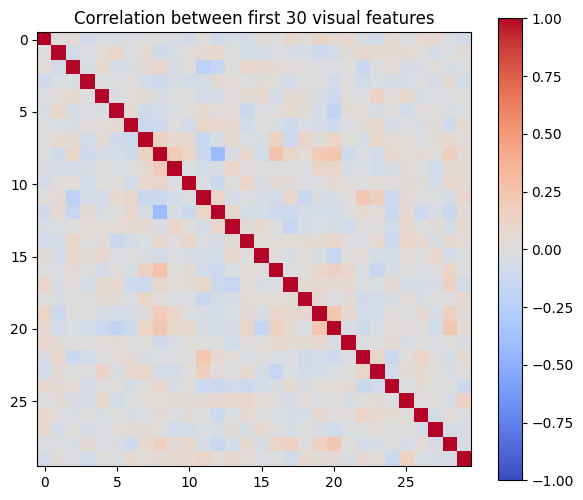

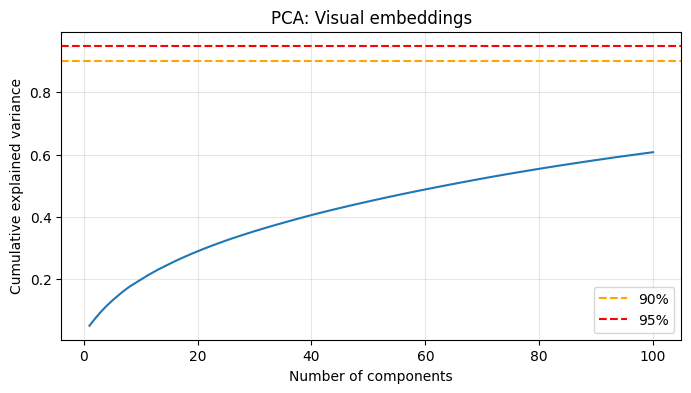

Variance explained by 100 components: 0.60757595


In [ ]:
visual_cols = [c for c in X_full.columns if str(c).startswith("video_emb_")]
V = X_full[visual_cols].to_numpy(dtype=np.float32)

print("Videos:", len(X_full))
print("Total features:", X_full.shape[1] - 1)
print("Visual features:", V.shape[1])
print("Missing values:", X_full.isna().sum().sum())
print("Duplicate IDs:", X_full["video_id"].duplicated().sum())

# Распределение значений
plt.figure(figsize=(8, 4))
plt.hist(V.ravel(), bins=100)
plt.title("Distribution of visual embedding values")
plt.xlabel("Embedding value")
plt.ylabel("Frequency")
plt.show()

# Корреляции между первыми 30 признаками
corr = np.corrcoef(V[:, :30], rowvar=False)

plt.figure(figsize=(7, 6))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar()
plt.title("Correlation between first 30 visual features")
plt.show()

# PCA
V_scaled = StandardScaler().fit_transform(V)

pca = PCA(n_components=min(100, V.shape[0], V.shape[1]))
Z = pca.fit_transform(V_scaled)

cumulative = np.cumsum(pca.explained_variance_ratio_)

plt.figure(figsize=(8, 4))
plt.plot(np.arange(1, len(cumulative)+1), cumulative)
plt.axhline(0.90, linestyle="--", color="orange", label="90%")
plt.axhline(0.95, linestyle="--", color="red", label="95%")
plt.xlabel("Number of components")
plt.ylabel("Cumulative explained variance")
plt.title("PCA: Visual embeddings")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print("Variance explained by 100 components:", cumulative[-1])

### Анализ визуальных эмбеддингов

Ну что, наконец-то мы добрались до визуальных эмбеддингов! Для нашего проекта они особенно важны, ведь в ютубе и тик токе пользователь в первую очередь видит само видео, а уже потом обращает внимание на описание и хештеги. Поэтому хочется посмотреть, что вообще представляют собой наши визуальные признаки и насколько они отличаются друг от друга.
Для начала посмотрим на размер нашей итоговой матрицы. У нас получилось 4514 видео и 1667 признаков, из которых 512 — визуальные эмбеддинги. Пропущенных значений нет, повторяющихся пйди тоже.отлично.

**Распределение значений визуальных эмбеддингов**

На первом графике видим довольно интересную картину: почти все значения сосредоточены около нуля, а чем дальше от него, тем реже они встречаются. Причём распределение выглядит довольно симметричным.
Кстати нормы наших эмбеддингов равны единице. То есть векторы уже нормализованы.


**Корреляция визуальных признаков**

Дальше посмотрим на корреляционную матрицу первых 30 визуальных признаков.

Красная диагональ это каждый признак идеально коррелирует сам с собой. А вот всё остальное интереснее. Видим, что большая часть ячеек довольно светлая, то есть сильных линейных зависимостей между выбранными координатами немного. Хотя местами встречаются и положительные, и отрицательные корреляции.
среди первых 30 координат мы не наблюдаем большого количества сильных корреляций.

Конечно, делать вывод обо всех 512 признаках по первым 30 было бы неправильно, поэтому идём дальше.

**PCA — насколько можно сократить наши 512 признаков?**

Вот тут уже становится интереснее! У нас 512 визуальных признаков на каждое видео, и возникает вполне логичный вопрос: а нужны ли нам все 512? Может, большую часть информации можно сохранить в гораздо меньшем количестве компонент?

Для этого применили PCA и посмотрели, какую долю общей дисперсии объясняют первые 100 главных компонент.
100 компонент объясняют только около 60,75% дисперсии.
То есть мы сократили количество визуальных признаков с 512 до 100, но при этом потеряли примерно 39,25% общей дисперсии.
На графике также видно, что кривая продолжает расти и даже не приближается к нашим порогам 90% и 95%. Значит, для сохранения такой доли дисперсии нам понадобится больше 100 компонент.

Это говорит о том, что вариативность визуальных эмбеддингов распределена по достаточно большому количеству направлений. И просто взять первые 50 или 100 компонент, рассчитывая сохранить почти всю дисперсию, у нас не получится.

Но есть ещё кое что. PCA вообще ничего не знает о популярности видео. Он сохраняет направления с наибольшей дисперсией, а не те, которые лучше всего помогают предсказывать просмотры. Поэтому даже если мы потеряем часть дисперсии, это не обязательно означает, что модель станет хуже.

**Вывод**

На данном этапе мы получили 4514 видео с полноценными визуальными эмбеддингами размерности 512 и объединили их с остальными признаками.

Анализ показал, что значения визуальных эмбеддингов в основном сосредоточены около нуля, нормы векторов равны единице, а среди первых 30 координат не наблюдается большой корреляцит.

PCA показал, что первые 100 компонент сохраняют около 60,75% общей дисперсии. Поэтому пока не будем спешить сокращать размерность. Для начала попробуем использовать все визуальные признаки, а уже затем сравним качество моделей с исходными эмбеддингами и с уменьшенной размерностью.

И, конечно, нужно учитывать, что сейчас мы работаем только с теми видео, для которых удалось получить визуальные эмбеддинги. Поэтому результаты этого анализа относятся к нашей подвыборке из 4514 видео, а не ко всему исходному датасету.

Missing views: 0
Negative views: 0
count         4,514.00
mean     23,351,967.49
std      36,795,483.21
min              21.00
25%         144,370.00
50%       5,156,652.50
75%      34,427,883.25
90%      68,268,736.20
95%      95,666,980.05
99%     164,717,919.61
max     351,377,643.00
Name: play_count, dtype: float64


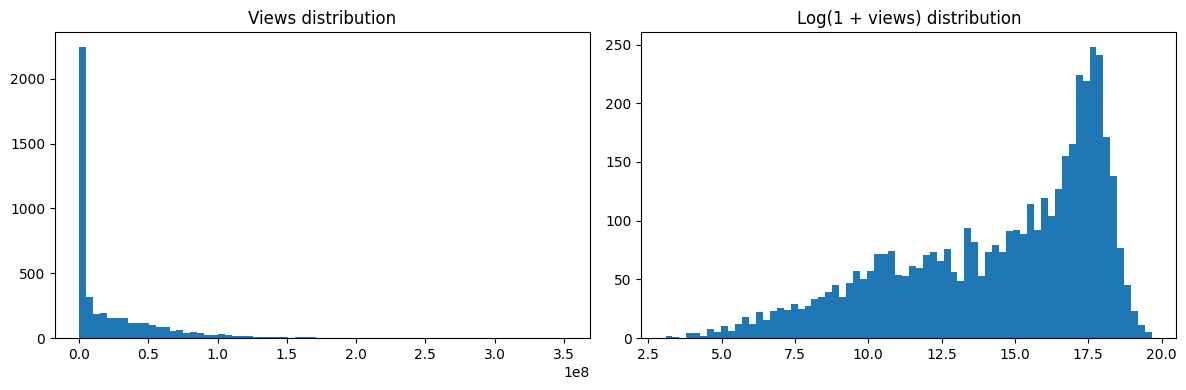

In [ ]:
target_df = df_plus_emb[["video_id", "play_count"]].copy()
target_df["video_id"] = target_df["video_id"].astype(str)

eda_df = X_full.merge(
    target_df,
    on="video_id",
    how="left",
    validate="one_to_one"
)

views = pd.to_numeric(eda_df["play_count"], errors="coerce")

print("Missing views:", views.isna().sum())
print("Negative views:", (views < 0).sum())

print(views.describe(
    percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
))

valid_views = views.dropna()
valid_views = valid_views[valid_views >= 0]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(valid_views, bins=70)
axes[0].set_title("Views distribution")

axes[1].hist(np.log1p(valid_views), bins=70)
axes[1].set_title("Log(1 + views) distribution")

plt.tight_layout()
plt.show()

### Анализ

Ну что, теперь самое интересное — просмотры! Ведь именно их мы в итоге и хотим предсказывать.

И тут сразу видно, насколько сильно наши видео отличаются друг от друга. У нас есть видео всего с 21 просмотром, а есть и настоящий гигант с **351 миллионом просмотров!** Разница, конечно, огромная.

При этом среднее количество просмотров у нас примерно 23,3 миллиона, а медиана всего 5,1 миллиона. То есть среднее почти в 5 раз больше медианы! Уже понятно, что несколько очень популярных видео сильно тянут среднее вверх.

Посмотрим на первый график. Тут вообще красота Огромная куча видео собралась слева, а дальше тянется длинный хвост вправо. Это скос вправо. Получается, что видео с относительно небольшим количеством просмотров у нас гораздо больше, чем настоящих вирусных хитов.

Например, 75% наших видео набрали меньше 34,4 миллиона просмотров, а 99% — меньше 164,7 миллиона. Но оставшийся 1% может набирать ещё больше!

Теперь посмотрим на второй график, где мы применили log1p к просмотрам.

Вот тут уже совсем другая картина! Видео наконец-то перестали толпиться в одном углу, и мы можем гораздо лучше рассмотреть распределение. Логарифм сжал огромные значения сильнее, чем маленькие, поэтому разница между видео с тысячами и сотнями миллионов просмотров уже не выглядит настолько чудовищной.

Правда, распределение всё равно не стало нормальным. Видно, что большая часть значений теперь находится справа, а хвост тянется влево. Но нам и не обязательно добиваться идеального холмика.

**Что по итогу**

Похоже, что работать с просмотрами в исходном масштабе будет непросто. У нас слишком большой разброс значений, и несколько вирусных видео могут сильно влиять на обучение модели, особенно если использовать MSE.

Будем использовать две модели. ридж и дами.
Но потом обязательно посмотрим на ошибки и сравним ленивость и старание.

И ещё один момент: сейчас мы анализируем только 4514 видео, для которых удалось получить визуальные эмбеддинги. Поэтому пока нельзя утверждать, что такое же распределение характерно для всего нашего датасета.

## ЧАСТЬ не знаю какая. Последняя. Время обучать модель

все , я столько сидела осмысляла всего, столько работы с признаками и их модификаци. и я просто не могу уйти не попробовав. Поехали!

In [215]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import Ridge
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

model_df = eda_df.copy()

feature_cols = X_full.columns.drop("video_id")

X_model = model_df[feature_cols].copy()
X_model.columns = X_model.columns.astype(str)

y = pd.to_numeric(model_df["play_count"], errors="coerce")

X_train, X_test, y_train, y_test = train_test_split(X_model, y,test_size=0.3,random_state=42)

models = {
    "Dummy_mod": DummyRegressor(strategy="mean"),
    "Ridge_mod": make_pipeline(StandardScaler(),Ridge(alpha=100.0))}

results = []

for name, model in models.items():

    model.fit(X_train, y_train)

    pred = model.predict(X_test)

    results.append({"Model": name,"MAE_log": mean_absolute_error(y_test, pred),"RMSE_log": np.sqrt(mean_squared_error(y_test, pred)),"R2_log": r2_score(y_test, pred)})

display(pd.DataFrame(results))

,Model,MAE_log,RMSE_log,R2_log
0,Dummy_mod,"24,644,243.50","32,444,411.73",-0.01
1,Ridge_mod,"25,149,469.63","33,908,844.16",-0.10


In [216]:
pred_ridge = models["Ridge_mod"].predict(X_test)
pred_dummy = models["Dummy_mod"].predict(X_test)

predictions = pd.DataFrame({
    "Real_views": y_test,
    "Dummy_prediction": pred_dummy,
    "Ridge_prediction": pred_ridge
})

display(predictions.head(20).round(0))

,Real_views,Dummy_prediction,Ridge_prediction
4235,33733975,"24,318,270.00","16,874,841.00"
798,1318902,"24,318,270.00","-9,801,606.00"
2321,3817815,"24,318,270.00","52,465,004.00"
3352,11547768,"24,318,270.00","6,844,231.00"
2304,7176,"24,318,270.00","3,415,605.00"
2554,9211789,"24,318,270.00","-49,072,702.00"
1606,427,"24,318,270.00","34,450,737.00"
3876,34403823,"24,318,270.00","52,508,092.00"
705,68492,"24,318,270.00","18,967,600.00"
3907,72619743,"24,318,270.00","42,435,376.00"


Почему я вообще взяла Дами модель. Потому что просто посмотреть и чтобы было с чем сравнить нашу модель которая прикладывает силы в обучении и предсказание!

честно говоря я в шоке и ожидала другого от ридж но что поделать. она старалась. хотя и проиграла самой ленивой модели на планете.

## Практическая применимость проекта

Время философии и заработка денег.

На самом деле применений довольно много. Например, представим человека, который ведёт тик ток и пытается развивать свой аккаунт. Он снимает видео, монтирует, подбирает музыку, пишет описание, а потом публикует и надеется, что оно наберёт просмотры. Но заранее он практически не знает, какое видео может понравиться аудитории, а какое останется незамеченным.

Вот здесь и могла бы пригодиться наша модель. Например, автор подготовил три варианта ролика с разным монтажом или первыми секундами. Он загружает их в систему, а модель анализирует визуальное содержимое, текст на видео, описание и другие доступные признаки. После этого она выдаёт прогноз популярности для каждого варианта.

Конечно, это не означает, что модель сможет гарантировать миллион просмотров. Но в идеале она могла бы помочь выбрать более перспективный вариант ещё до публикации.

**Кому ещё это может быть полезно?**

Например, рекламным агентствам и компаниям, которые постоянно создают короткие видео для продвижения товаров. У них могут быть десятки вариантов рекламы, и проверять каждый на реальной аудитории довольно дорого. Такая модель могла бы стать дополнительным инструментом для предварительного отбора роликов.

**А насколько реально всё это реализовать?**

Технически вполне реально. Я уже научилпсь извлекать текстовые и визуальные эмбеддинги, объединять их с другими характеристиками и передавать модели.

В дальнейшем можно было бы сделать простой сервис: пользователь загружает видео, добавляет описание и хештеги, а система автоматически извлекает признаки и выдаёт прогноз.

Но здесь есть несколько серьёзных сложностей.

во первых, популярность зависит не только от самого видео. На неё влияют аудитория автора, актуальные тренды, алгоритмы платформы и даже случайность. Два практически одинаковых видео могут получить совершенно разное количество просмотров.

Во вторых, у нашего датасета есть ограничение: мы не знаем точную дату сбора статистики для каждого ролика. Поэтому видео, опубликованное несколько лет назад, могло накопить больше просмотров просто потому, что существовало дольше. В идеале нам нужны просмотры за одинаковый промежуток времени после публикации, например за первые 24 часа или 7 дней илт 30.

В третьих, у нас нет информации о показах и CTR. А ведь количество просмотров зависит в том числе от того, сколько раз платформа вообще показала видео пользователям. Поэтому пока мы пытаемся предсказывать итоговое количество просмотров, а не вероятность того, что конкретный пользователь заинтересуется роликом.

Есть и технические сложности. Обработка видео требует вычислительных ресурсов, а извлечение эмбеддингов занимает время. Как я в гугл колабе сидела с первыми 5 секундами и эмбендингом... Если пользователей будет много, придётся думать о скорости обработки, стоимости серверов и хранении данных.

Также нельзя забывать о конфиденциальности и авторских правах. Пользователи могут загружать личные или ещё не опубликованные видео, поэтому нужно обеспечить безопасное хранение и удаление файлов. А для обучения на чужих видео важно учитывать условия использования данных и права их владельцев.

**наша модель действительно полезна?**

Полезна. Нужно толлько доработать и знаний больше нужно. Но в целом очень даже полезна.наши первые эксперименты с Ridge пока не показали улучшения относительно DummyRegressor. Поэтому говорить, что у нас уже есть готовое работающее решение неправильно. Нам ещё предстоит проверить другие подходы и понять, насколько хорошо популярность вообще можно предсказывать по доступным признакам. ЕЩе надо учитывать тамб нейл например но это у длиных видео. а у шорт этот признак не важен.

При этом нужно учитывать, что разные аккаунты имеют разную аудиторию, поэтому сравнивать результаты без дополнительных условий будет не корректно.

В итоге я вижу наш проект как инструмент, который помогает принимать решения, и создать сориентироваться во время создания и публикации видео.

Пока у нас только первые эксперименты, но сама идея вполне имеет практический смысл. Если удастся добиться качества лучше простых базовых подходов и проверить модель на новых данных, её можно будет использовать для предварительной оценки коротких видео и выбора наиболее перспективных вариантов перед публикацией. Я еще сделаю эмбендинги для все наших 50к с лишним видео. И поработаю на досуге об улучшениях. к след чек поинту будут у нас все видео из этого датасета в цифрах